In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
import matplotlib.pyplot as plt

# Load your dataset
data = pd.read_csv('2yr.txt', delimiter=',')
#data1 = pd.read_excel('Michael_Model_RUN-6-7.xlsx', sheet_name='2Lines-fake_Training_data')
#data = data.append(data1)
data['TM_STAMP'] = (pd.to_datetime(data['TM_STAMP']).astype('int64') // 10**9)
data=data.dropna()

In [2]:
data


,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,SIG2NOISE,REPORTABLE
0,0,392,1609459200,8679.682617,3.0000,580.325806,True
1,1,392,1609462800,8679.713867,3.0000,536.404236,True
2,2,392,1609466400,8679.676758,3.0000,758.372925,True
3,3,392,1609470000,8679.657227,3.0000,615.265381,True
4,4,392,1609473600,8679.676758,3.0000,718.530701,True
...,...,...,...,...,...,...,...
21563833,22316173,1865,1629388800,8095.556152,3.0625,440.103363,True
21563834,22316174,1865,1629392400,8095.541992,3.0625,439.114838,True
21563835,22316175,1865,1629396000,8095.513184,3.0625,397.749268,True
21563836,22316176,1865,1629399600,8095.538086,3.0625,520.950989,True


In [3]:
# Preprocess the data
from sklearn.utils import shuffle
X = data[['DIGITS','AMP','SIG2NOISE']]
y = data['REPORTABLE']
X, y = shuffle(X, y, random_state=42)
X

,DIGITS,AMP,SIG2NOISE
20029522,8456.794922,2.879588,4860.184570
12573319,8180.598633,2.687500,11.757433
495895,-99.000000,0.000000,2.236708
16542041,7737.115723,3.875000,248.603821
3313758,9010.609375,3.317972,6322.283691
...,...,...,...
14824757,8762.758789,3.000000,388.905212
2276863,8182.402832,3.000000,524.477112
13546490,8938.275391,2.434754,4639.340820
21435610,-99.000000,0.000000,2.707804


In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(X)


In [5]:
# stratify - make sure classes are evenlly represented across splits
X_train, X_valid, y_train, y_valid = \
    train_test_split(X, y, stratify=y, train_size=0.75)

In [6]:
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Dropout
from tensorflow.keras.models import Model


visible = Input(shape=(X_train.shape[1],))
hidden1 = Dense(256, activation='relu')(visible)
#hidden1 = BatchNormalization()(hidden1)
#hidden1 = Dropout(0.3)(hidden1)

hidden2 = Dense(256, activation='relu')(hidden1)
#hidden2 = BatchNormalization()(hidden2)
#hidden2 = Dropout(0.3)(hidden2)


output = Dense(1, activation='sigmoid')(hidden2)

model = Model(inputs=visible, outputs=output)

In [7]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['binary_accuracy'],
)

In [8]:
from tensorflow import keras
early_stopping = keras.callbacks.EarlyStopping(
    patience=5,
    min_delta=0.001,
    restore_best_weights=True,
)

In [9]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=512,
    epochs=20,
    callbacks=[early_stopping],
)

Epoch 1/20
31069/31069 [==============================] - 203s 6ms/step - loss: 0.0241 - binary_accuracy: 0.9971 - val_loss: 0.0122 - val_binary_accuracy: 0.9970
Epoch 2/20
31069/31069 [==============================] - 196s 6ms/step - loss: 0.0229 - binary_accuracy: 0.9979 - val_loss: 0.0086 - val_binary_accuracy: 0.9983
Epoch 3/20
31069/31069 [==============================] - 190s 6ms/step - loss: 0.0104 - binary_accuracy: 0.9981 - val_loss: 0.0083 - val_binary_accuracy: 0.9983
Epoch 4/20
31069/31069 [==============================] - 191s 6ms/step - loss: 0.0087 - binary_accuracy: 0.9982 - val_loss: 0.0084 - val_binary_accuracy: 0.9981
Epoch 5/20
31069/31069 [==============================] - 186s 6ms/step - loss: 0.0081 - binary_accuracy: 0.9982 - val_loss: 0.0082 - val_binary_accuracy: 0.9982
Epoch 6/20
31069/31069 [==============================] - 190s 6ms/step - loss: 0.0080 - binary_accuracy: 0.9982 - val_loss: 0.0072 - val_binary_accuracy: 0.9985
Epoch 7/20
31069/31069 [====

<Axes: title={'center': 'Accuracy'}>

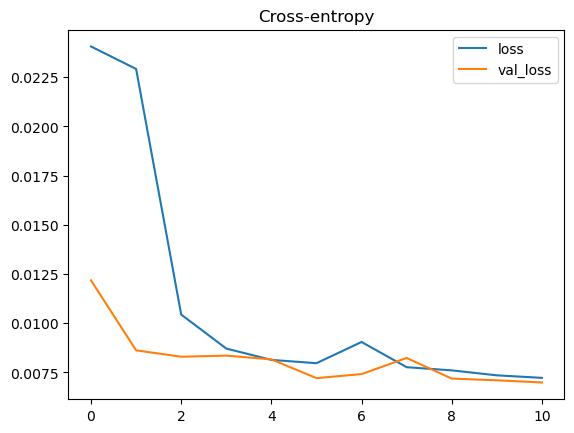

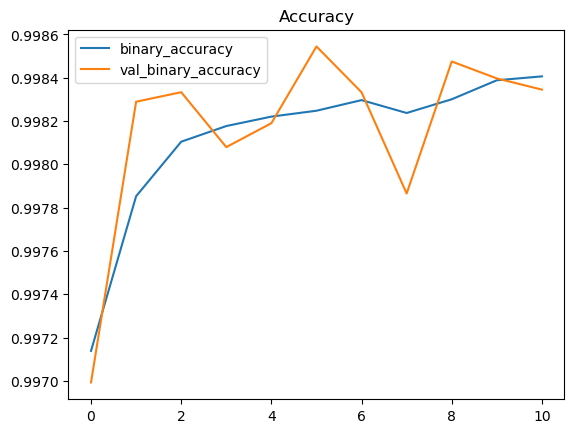

In [10]:
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot(title="Cross-entropy")
history_df.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot(title="Accuracy")

In [11]:
val = pd.read_csv('Q1_2023.txt', delimiter=',')
val['TM_STAMP'] = (pd.to_datetime(val['TM_STAMP']).astype('int64') // 10**9)
val=val.dropna()

In [12]:
val_y1 = val['REPORTABLE']                   #.astype('float')
val_x1 = val[['DIGITS','AMP','SIG2NOISE']]

val_x1 = scaler.transform(val_x1)

In [13]:
pred_val = model.evaluate(val_x1, val_y1)

72732/72732 [==============================] - 127s 2ms/step - loss: 0.0105 - binary_accuracy: 0.9980


In [14]:
pre_val= model.predict(val_x1)
pre_val

72732/72732 [==============================] - 115s 2ms/step


array([[0.9999677 ],
       [0.99996763],
       [0.99997   ],
       ...,
       [0.9999215 ],
       [0.9999153 ],
       [0.99988264]], dtype=float32)

In [15]:
for i in range(len(pre_val)):
    if pre_val[i] >= 0.5:
        pre_val[i] = 1
    else:
        pre_val[i] = 0

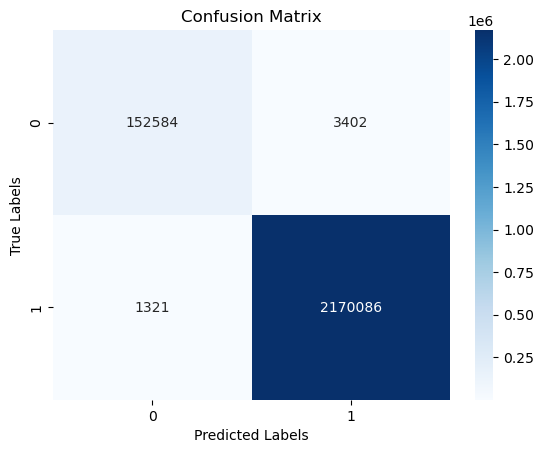

In [17]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(val_y1, pre_val)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [19]:
# Add the predictions to the new dataset
val['PREDICTIONS'] = pre_val

val['TM_STAMP'] = pd.to_datetime(val['TM_STAMP'], unit='s')
val

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,SIG2NOISE,REPORTABLE,PREDICTIONS
0,0,1109,2023-01-01 01:00:00,8584.845703,2.8750,340.585815,True,1.0
1,1,1109,2023-01-01 02:00:00,8584.845703,2.8750,339.820831,True,1.0
2,2,1109,2023-01-01 03:00:00,8584.852539,2.8750,382.831604,True,1.0
3,3,1109,2023-01-01 04:00:00,8584.845703,2.8750,468.703766,True,1.0
4,4,1101,2023-01-01 00:00:00,8789.166016,2.6875,306.427765,True,1.0
...,...,...,...,...,...,...,...,...
2340679,2428837,1182,2023-01-11 02:00:00,8937.125977,2.3125,303.683960,True,1.0
2340682,2428840,1182,2023-01-12 03:00:00,8937.468750,2.3125,286.438416,True,1.0
2340684,2428842,1182,2023-01-12 14:00:00,8937.841797,2.3125,203.513748,True,1.0
2340685,2428843,1182,2023-01-12 16:00:00,8937.884766,2.3125,280.699860,True,1.0


In [20]:
val['REPORTABLE'] =val['REPORTABLE'].astype('float')

In [21]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Assuming you already have the new_data dataframe
# Step 2: Create a new column to store the comparison results
val['COMPARE'] = val['REPORTABLE'] == (val['PREDICTIONS'] == 1)

# Get unique ID_PIEZO values for predicted false and actual REPORTABLE false
predicted_false = val.loc[val['PREDICTIONS'] == 0, 'ID_PIEZO'].unique()
actual_reportable_false = val.loc[val['REPORTABLE'] == False, 'ID_PIEZO'].unique()

# Save the unique ID_PIEZO's for predicted false and actual REPORTABLE false in separate text files
with open("PIEZO_Predicted_False.txt", 'w') as f:
    for id_piezo in predicted_false:
        f.write(str(id_piezo) + '\n')

with open("Actual_Piezo_Reportable_False.txt", 'w') as f:
    for id_piezo in actual_reportable_false:
        f.write(str(id_piezo) + '\n')

# Step 4: Create a confusion matrix
y_true = val['REPORTABLE']
y_pred = val['PREDICTIONS'].apply(lambda x: x == 1)  # Convert 1's and 0's to boolean values
cm = confusion_matrix(y_true, y_pred)

# Create a labeled confusion matrix using a Pandas DataFrame
labeled_cm = pd.DataFrame(cm, index=['Actual: False', 'Actual: True'], columns=['Predicted: False', 'Predicted: True'])

print("Confusion Matrix:")
print(labeled_cm)

Confusion Matrix:
               Predicted: False  Predicted: True
Actual: False            152584             3402
Actual: True               1321          2170086


In [22]:
# importing os module
# Directory
import shutil
import os
directory = "ML_FIGURES"

 

dir ="C:/Temp/ML_FIGURES_check"
if os.path.exists(dir):
    shutil.rmtree(dir)
os.makedirs(dir)

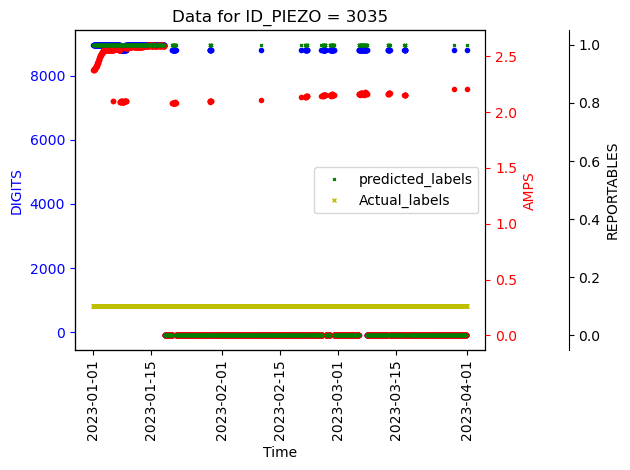

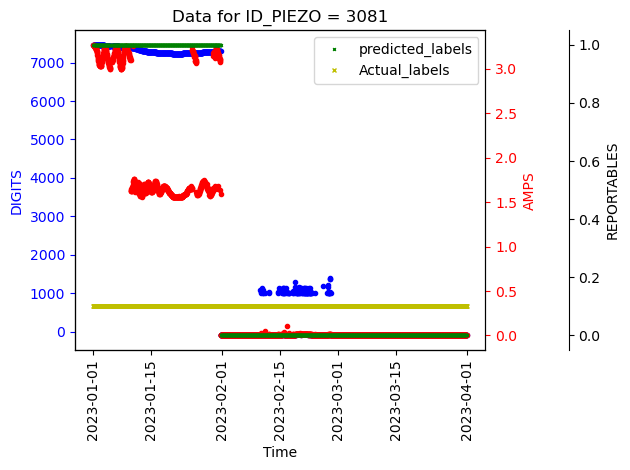

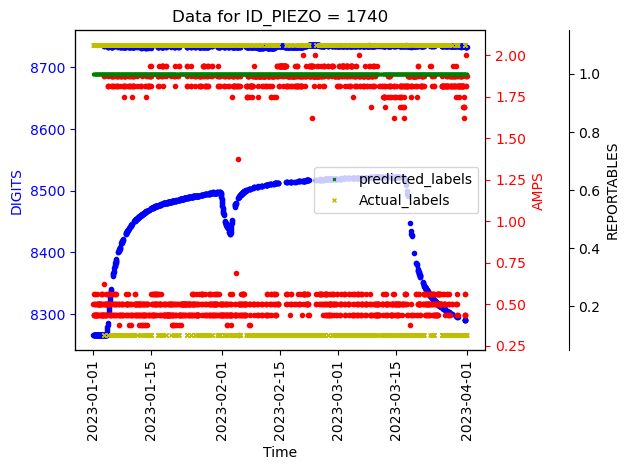

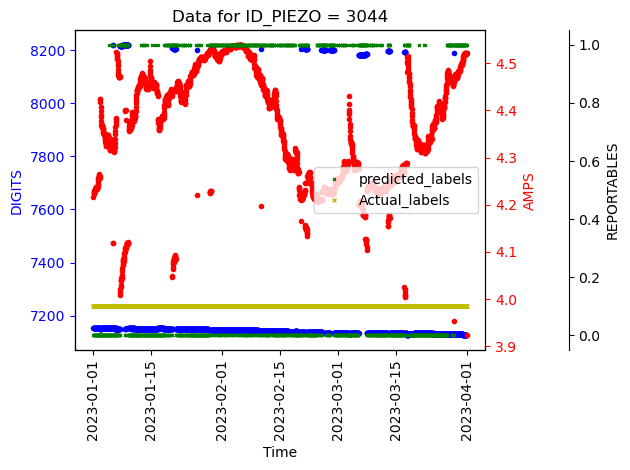

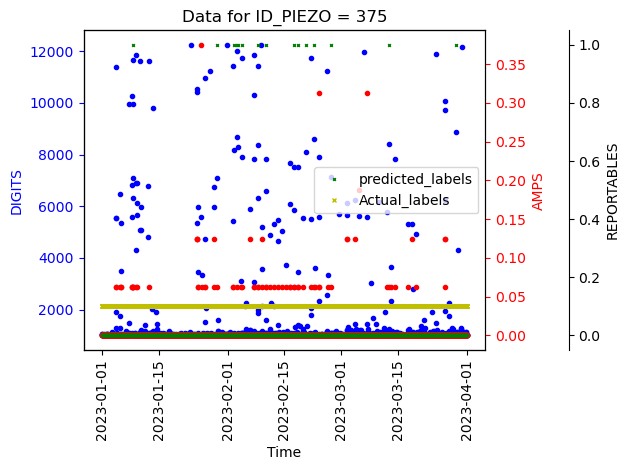

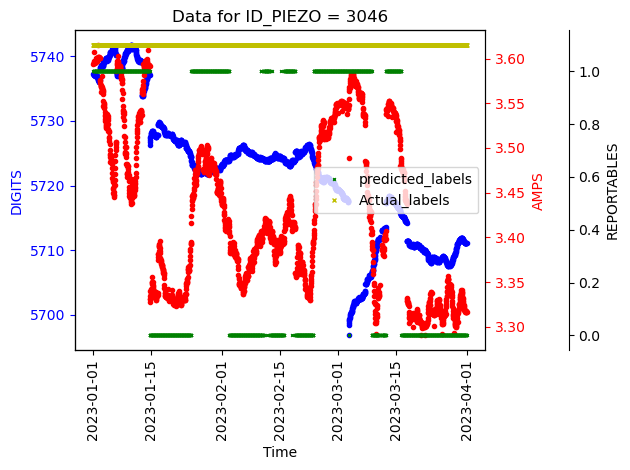

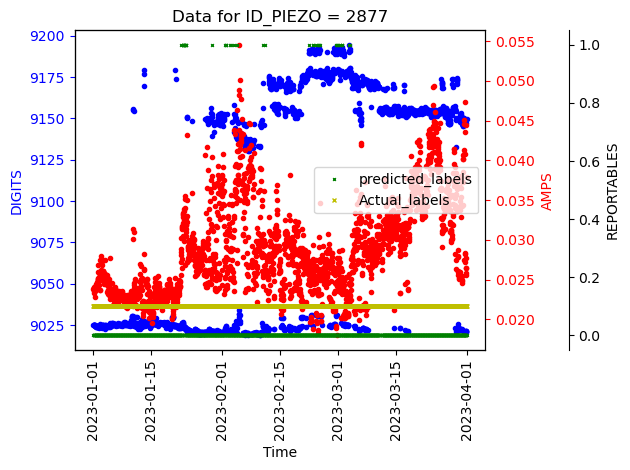

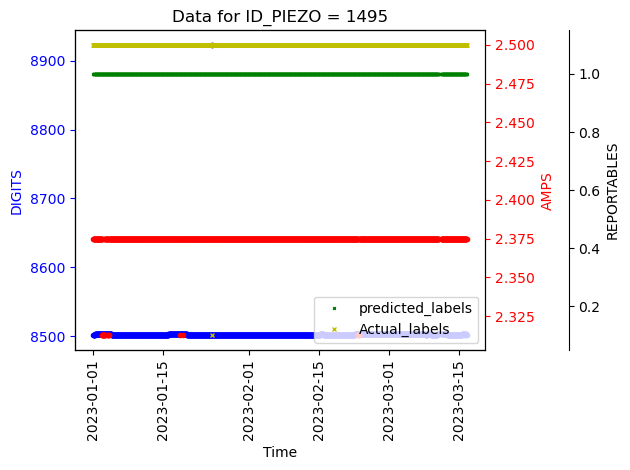

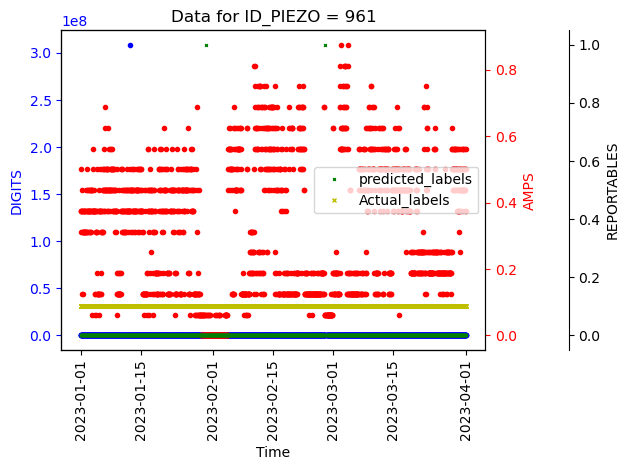

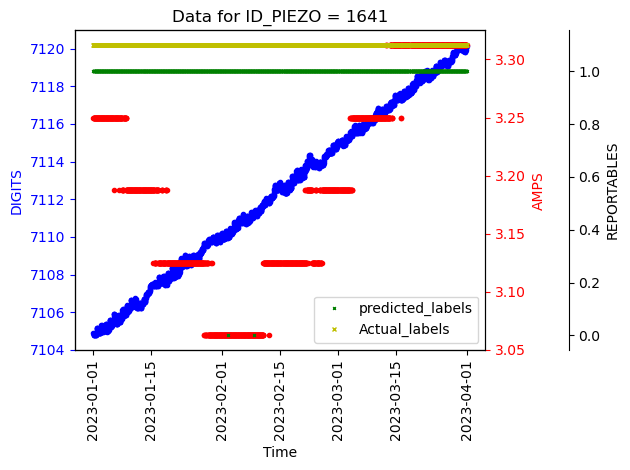

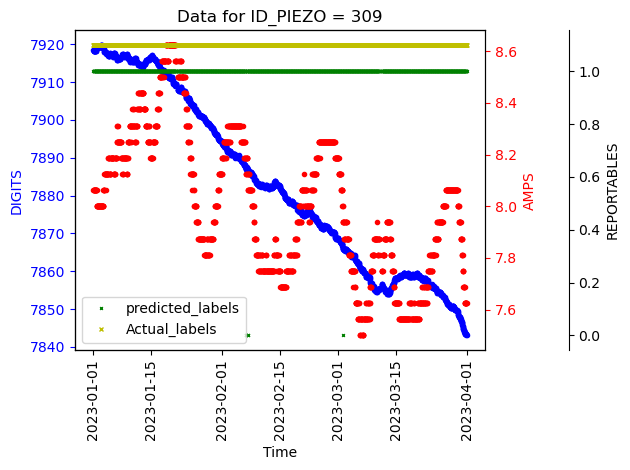

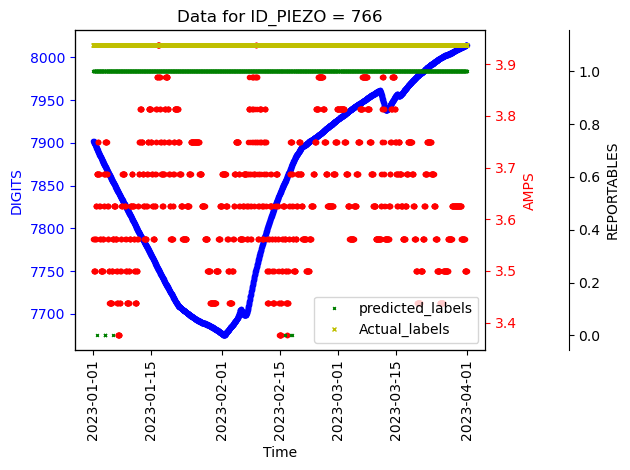

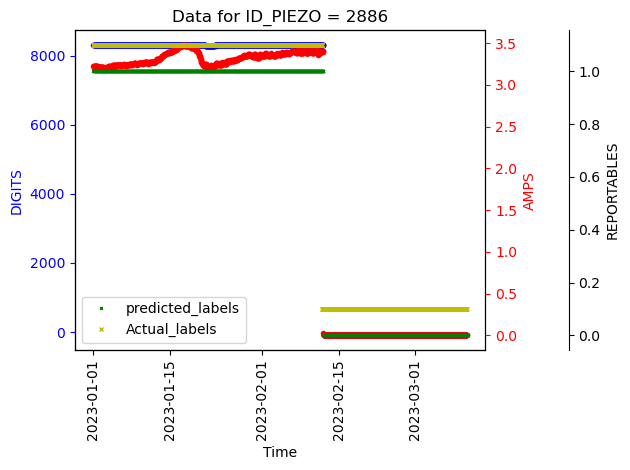

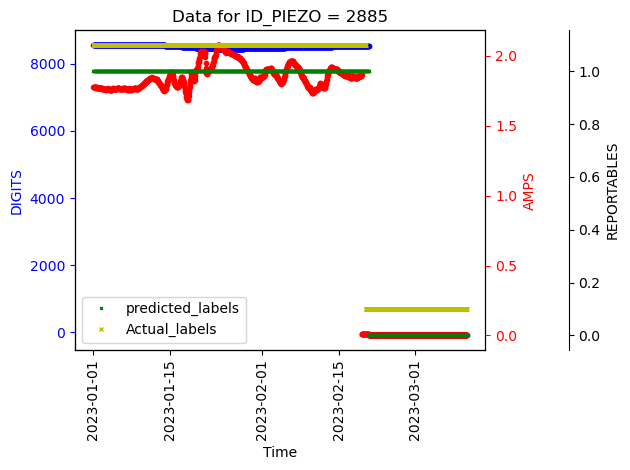

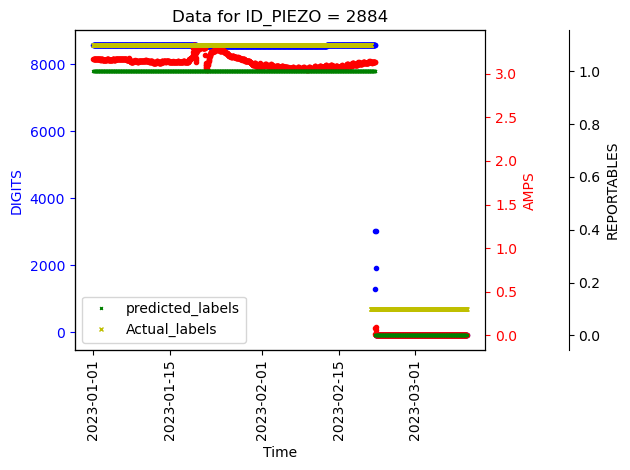

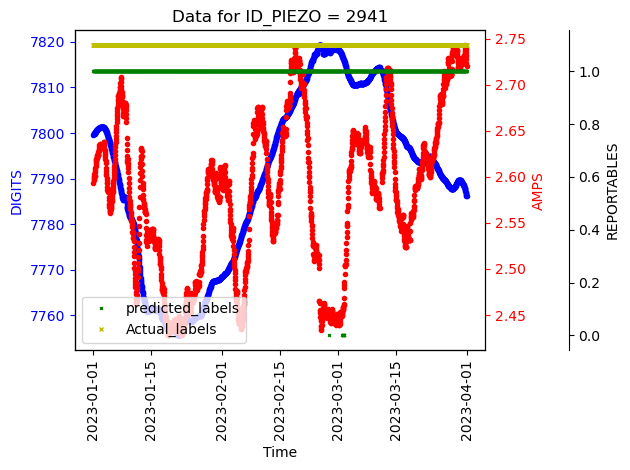

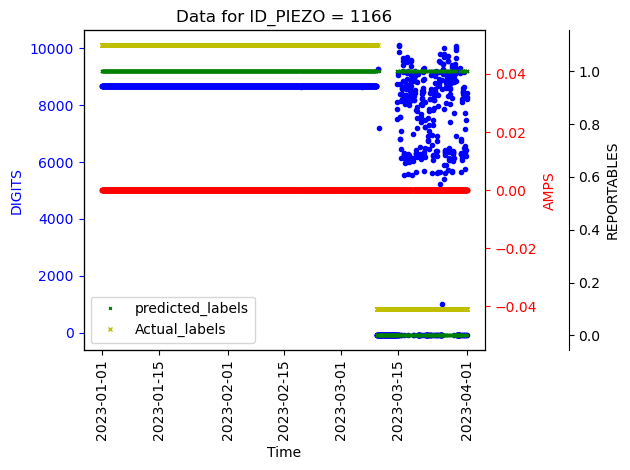

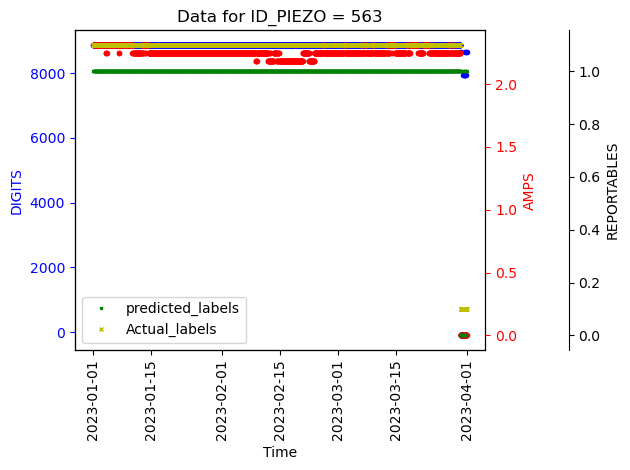

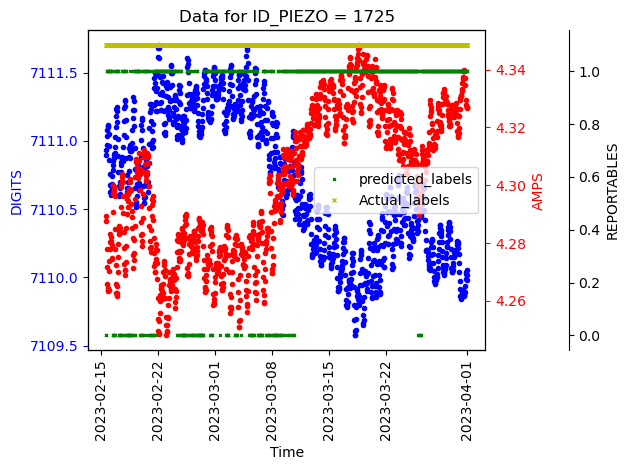

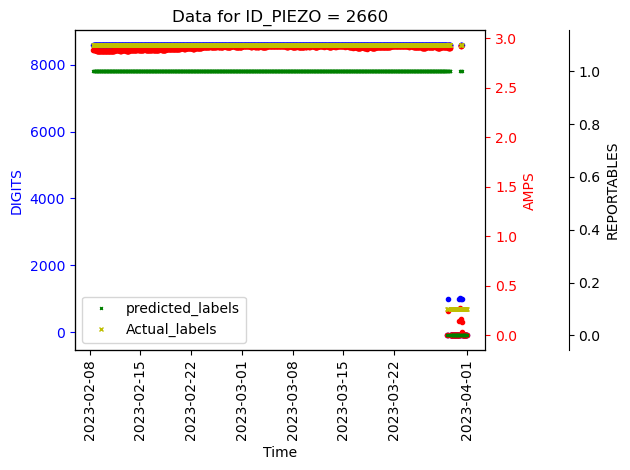

In [23]:
import matplotlib.pyplot as plt

val['REPORTABLE']=val['REPORTABLE']+0.1

# Filter the dataframe

filtered_df = val[val['COMPARE'] == False]

 

# Get the unique 'ID_PIEZO' values

unique_ids = filtered_df['ID_PIEZO'].unique()



# Plot data for each unique 'ID_PIEZO'

for id in unique_ids:

    # Filter dataframe for the current 'ID_PIEZO'

    df_id = val[val['ID_PIEZO'] == id]
 

    # Create a new figure and two subplots, sharing x-axis

    fig, ax1 = plt.subplots()

 

    # First subplot for 'X' values

    ax1.plot(df_id['TM_STAMP'], df_id['DIGITS'], 'bo', markersize=3)

    ax1.set_xlabel('Time')
    plt.xticks(rotation=90)

    # Make the y-axis label and line color blue to match the line color.

    ax1.set_ylabel('DIGITS', color='b')

    ax1.tick_params('y', colors='b')

 
    # Second subplot for 'Y' values, sharing the same x-axis

    ax2 = ax1.twinx()

    ax2.plot(df_id['TM_STAMP'], df_id['AMP'], 'ro', markersize=3)

    # Make the y-axis label and line color red to match the line color.

    ax2.set_ylabel('AMPS', color='r')

    ax2.tick_params('y', colors='r')
    
    # Create a third axis sharing the same x-axis
    ax3 = ax1.twinx()

    # Offset the third axis
    ax3.spines['right'].set_position(('outward', 60))

    # Plot data on the third axis
    ax3.plot(df_id['TM_STAMP'],df_id['PREDICTIONS'],'gx', markersize=2, label='predicted_labels')
    ax3.plot(df_id['TM_STAMP'],df_id['REPORTABLE'],'yx', markersize=3, label='Actual_labels')
    ax3.set_ylabel('REPORTABLES', color='black')
    ax3.tick_params('y', colors='black')
    
    # Add a legend
    lines = ax3.get_lines()
    ax3.legend(lines, [line.get_label() for line in lines])
    # Add a title to the plot

    plt.title(f"Data for ID_PIEZO = {id}")


    fig.tight_layout()  # This ensures the right y-label is not cut off
    


    plt.show()
    #
    fig.savefig('C:\Temp\ML_FIGURES_check\{0}.png'.format(id), bbox_inches='tight',dpi=300)